# Hands-on: Filtering dan Edge Detection

Study group IMV Laboratory.

**Alur notebook:**
1. Konvolusi 2D manual pakai loop (fondasi untuk semua yang lain)
2. Filtering: mean, Gaussian, median, sharpening
3. Edge detection: Sobel, Prewitt, Laplacian/LoG, Canny
4. Perbandingan akhir dan latihan

**Library yang dipakai:**
- `numpy`: array, operasi matematika, padding
- `opencv-python` (`cv2`): pembanding hasil manual (`filter2D`, `GaussianBlur`, `medianBlur`, `Sobel`, `Canny`)
- `matplotlib`: menampilkan gambar dan perbandingan
- `scikit-image`: hanya untuk gambar contoh bawaan (`data.camera()`), jadi tidak perlu upload file
- `time`: mengukur kecepatan loop manual vs OpenCV
- `numba` (opsional): mengompilasi loop manual supaya jauh lebih cepat. Kalau tidak terpasang, kode tetap jalan dengan Python murni (lebih lambat)

Install jika belum ada: `pip install numpy opencv-python matplotlib scikit-image numba`

In [ ]:
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

# numba opsional: kalau ada, loop manual dikompilasi (jauh lebih cepat)
try:
    from numba import njit
    HAS_NUMBA = True
except ImportError:
    HAS_NUMBA = False

    def njit(*args, **kwargs):  # pengganti kosong: fungsi jalan sebagai Python biasa
        if len(args) == 1 and callable(args[0]):
            return args[0]
        return lambda f: f

print('numba tersedia:', HAS_NUMBA)

plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(42)  # seed supaya hasil noise bisa diulang

numba tersedia: True


## 0. Persiapan: gambar dan fungsi bantu

Gambar otomatis diperkecil ke maksimal 256 piksel di sisi terpanjang lewat `resize_max`, supaya loop manual tidak terlalu lama. **Jangan masukkan gambar besar tanpa `resize_max`**: gambar 12 megapiksel bisa membuat satu sel berjalan berpuluh menit. Untuk gambar sendiri, ganti baris `img = ...` dengan `img = resize_max(cv2.imread('namafile.jpg', cv2.IMREAD_GRAYSCALE))`.

(255, 184) uint8 0 254


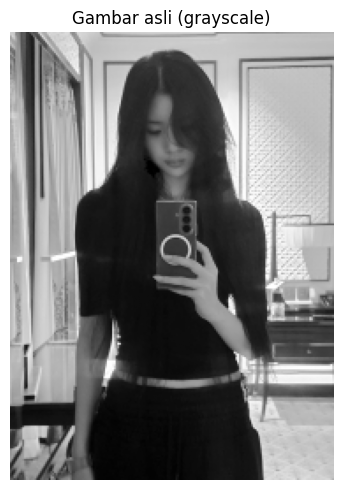

In [ ]:
def resize_max(a, max_side=256):
    # Perkecil gambar kalau sisi terpanjangnya > max_side (loop manual lambat untuk gambar besar)
    h, w = a.shape[:2]
    scale = max_side / max(h, w)
    if scale >= 1:
        return a
    return cv2.resize(a, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)


img = resize_max(cv2.imread('h2hjuun.jpg', cv2.IMREAD_GRAYSCALE))  # grayscale uint8
# Gambar sendiri: img = resize_max(cv2.imread('gambarku.jpg', cv2.IMREAD_GRAYSCALE))
print(img.shape, img.dtype, img.min(), img.max())


def to_uint8(a):
    # Clip ke 0-255 lalu ubah ke uint8 (hindari overflow/wrap-around)
    return np.clip(a, 0, 255).astype(np.uint8)


def normalize_to_uint8(a):
    # Skala nilai apa pun (mis. gradien) ke rentang 0-255
    a = a.astype(np.float64)
    a = a - a.min()
    if a.max() > 0:
        a = a / a.max() * 255
    return a.astype(np.uint8)


def show(images, titles, cols=3, size=(4, 4)):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size[0] * cols, size[1] * rows))
    axes = np.array(axes).reshape(-1)
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(t)
        ax.axis('off')
    for ax in axes[len(images):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def psnr(a, b):
    # Makin tinggi makin mirip dengan gambar referensi
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255 ** 2 / mse)


show([img], ['Gambar asli (grayscale)'], cols=1, size=(5, 5))

## 1. Konvolusi 2D manual pakai loop

Untuk setiap piksel (y, x), geser kernel ke atas piksel itu, kalikan elemen yang bersesuaian, lalu jumlahkan.

Poin penting:
- **Padding** supaya piksel pinggir tetap punya tetangga (zero, replicate, reflect)
- **Flip kernel** untuk konvolusi sejati (tanpa flip, itu korelasi)
- **Float64** untuk hasil antara, lalu clip saat ditampilkan

In [ ]:
@njit
def _convolve_loops(padded, flipped, h, w):
    # Inti konvolusi: 4 loop bersarang (di-compile numba jika tersedia)
    kh, kw = flipped.shape
    out = np.zeros((h, w), dtype=np.float64)
    for y in range(h):
        for x in range(w):
            s = 0.0
            for i in range(kh):
                for j in range(kw):
                    s += padded[y + i, x + j] * flipped[i, j]
            out[y, x] = s
    return out


def convolve2d(image, kernel, padding='reflect'):
    image = image.astype(np.float64)
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2

    mode = {'zero': 'constant', 'replicate': 'edge', 'reflect': 'reflect'}[padding]
    padded = np.pad(image, ((ph, ph), (pw, pw)), mode=mode)

    flipped = np.ascontiguousarray(np.flipud(np.fliplr(kernel)), dtype=np.float64)  # konvolusi = korelasi dgn kernel di-flip

    h, w = image.shape
    return _convolve_loops(padded, flipped, h, w)

### Verifikasi terhadap OpenCV

`cv2.filter2D` sebenarnya menghitung **korelasi**, jadi untuk membandingkan dengan konvolusi sejati kernel perlu di-flip dulu. `np.pad(mode='reflect')` setara dengan `cv2.BORDER_REFLECT_101`.

Selisih maksimum manual vs OpenCV: 0.00e+00
Waktu manual : 0.003 s
Waktu OpenCV : 0.00071 s  (sekitar 4x lebih cepat)


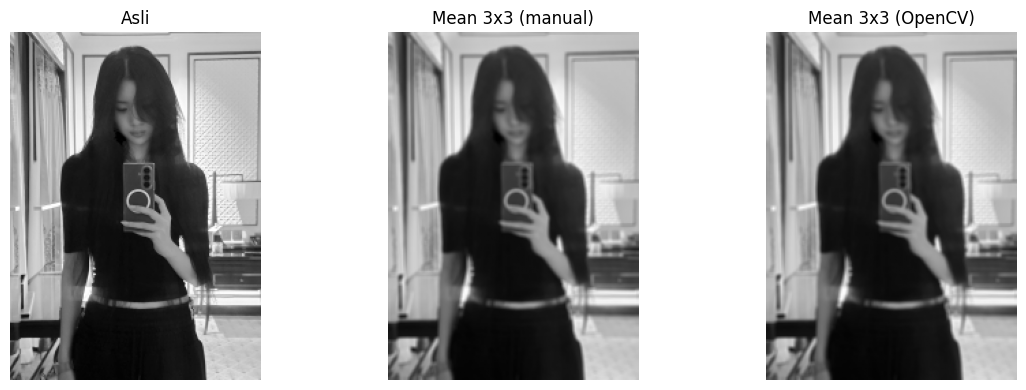

In [ ]:
k_mean = np.ones((3, 3)) / 9.0
convolve2d(img[:8, :8], k_mean)  # pemanasan: pemanggilan pertama ikut mengompilasi (numba), jangan diukur

t0 = time.time()
manual = convolve2d(img, k_mean, padding='reflect')
t_manual = time.time() - t0

t0 = time.time()
ref = cv2.filter2D(img.astype(np.float64), -1, np.flipud(np.fliplr(k_mean)),
                   borderType=cv2.BORDER_REFLECT_101)
t_cv = time.time() - t0

print(f'Selisih maksimum manual vs OpenCV: {np.abs(manual - ref).max():.2e}')
print(f'Waktu manual : {t_manual:.3f} s')
print(f'Waktu OpenCV : {t_cv:.5f} s  (sekitar {t_manual / max(t_cv, 1e-9):.0f}x lebih cepat)')

show([img, to_uint8(manual), to_uint8(ref)], ['Asli', 'Mean 3x3 (manual)', 'Mean 3x3 (OpenCV)'])

### Pengaruh border handling

Perhatikan tepi gambar. Zero padding membuat tepi menggelap karena tetangga di luar gambar dianggap 0.

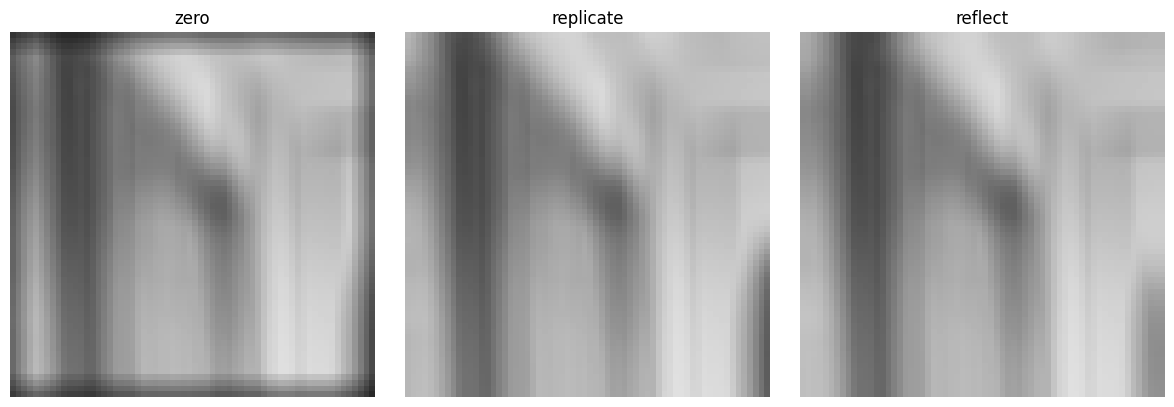

In [ ]:
k_big = np.ones((9, 9)) / 81.0  # kernel besar supaya efek tepi jelas
small = img[:64, :64]           # potongan kecil agar cepat

res = [convolve2d(small, k_big, padding=p) for p in ['zero', 'replicate', 'reflect']]
show([to_uint8(r) for r in res], ['zero', 'replicate', 'reflect'])

## 2. Filtering

Siapkan dulu dua jenis noise: Gaussian noise dan salt-and-pepper.

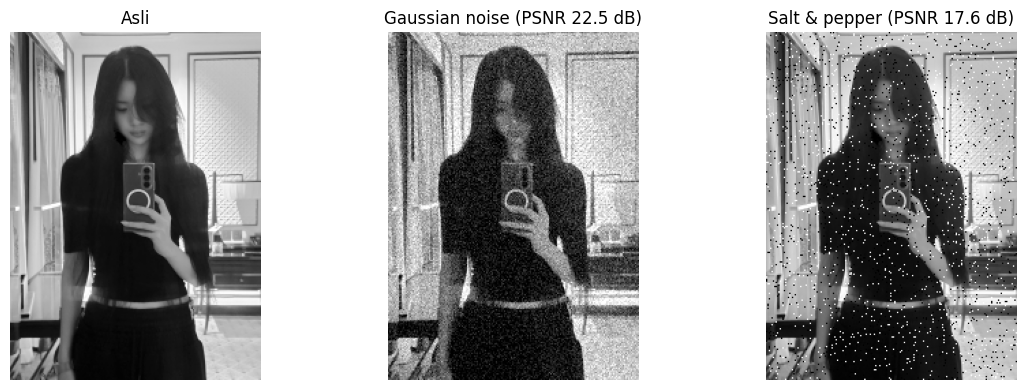

In [ ]:
def add_gaussian_noise(image, sigma=20):
    return to_uint8(image + rng.normal(0, sigma, image.shape))


def add_salt_pepper(image, amount=0.05):
    out = image.copy()
    r = rng.random(image.shape)
    out[r < amount / 2] = 0
    out[r > 1 - amount / 2] = 255
    return out


noisy_g = add_gaussian_noise(img, sigma=20)
noisy_sp = add_salt_pepper(img, amount=0.05)

show([img, noisy_g, noisy_sp],
     ['Asli', f'Gaussian noise (PSNR {psnr(img, noisy_g):.1f} dB)',
      f'Salt & pepper (PSNR {psnr(img, noisy_sp):.1f} dB)'])

### 2.1 Mean dan Gaussian filter (linear, low-pass)

Kernel Gaussian dibuat sendiri dari rumus, lalu dinormalisasi supaya jumlah bobot = 1.

In [ ]:
def gaussian_kernel(size=5, sigma=1.0):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma ** 2))
    return k / k.sum()


print(np.round(gaussian_kernel(5, 1.0), 4))
print('Jumlah bobot:', gaussian_kernel(5, 1.0).sum())

[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]
Jumlah bobot: 1.0


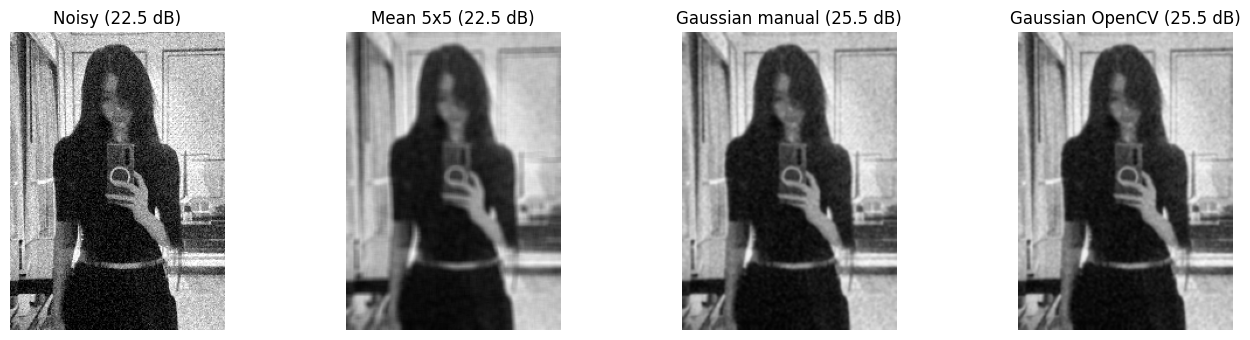

In [ ]:
mean_out = to_uint8(convolve2d(noisy_g, np.ones((5, 5)) / 25.0))
gauss_out = to_uint8(convolve2d(noisy_g, gaussian_kernel(5, 1.0)))
gauss_cv = cv2.GaussianBlur(noisy_g, (5, 5), 1.0)

show([noisy_g, mean_out, gauss_out, gauss_cv],
     [f'Noisy ({psnr(img, noisy_g):.1f} dB)',
      f'Mean 5x5 ({psnr(img, mean_out):.1f} dB)',
      f'Gaussian manual ({psnr(img, gauss_out):.1f} dB)',
      f'Gaussian OpenCV ({psnr(img, gauss_cv):.1f} dB)'], cols=4, size=(3.5, 3.5))

**Eksperimen:** coba ubah `sigma` (0.5, 1, 2, 3) dan ukuran kernel. Apa yang terjadi pada noise dan ketajaman detail?

### 2.2 Median filter (non-linear)

Median tidak bisa ditulis sebagai konvolusi, karena hasilnya bukan jumlah berbobot. Di sini kita ambil nilai tengah dari jendela. Bandingkan dengan mean pada salt-and-pepper.

Median manual sama dengan OpenCV: True


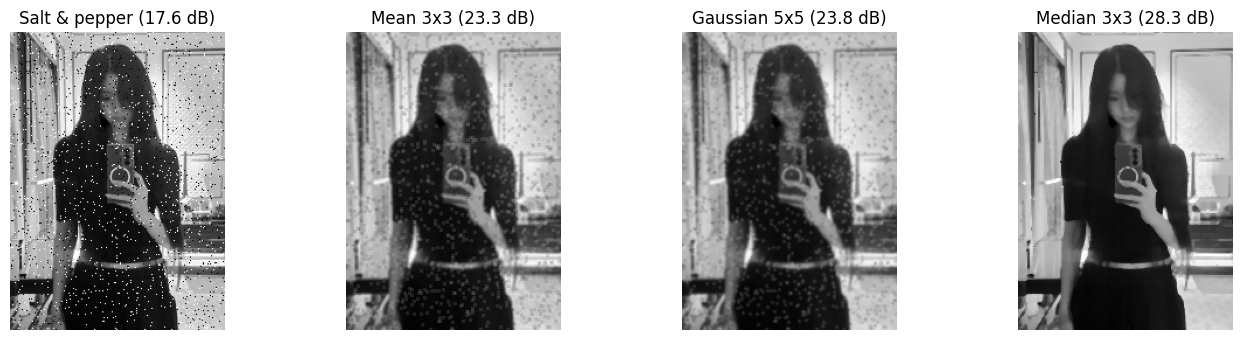

In [ ]:
@njit
def _median_loops(padded, size, h, w):
    out = np.zeros((h, w), dtype=padded.dtype)
    for y in range(h):
        for x in range(w):
            window = padded[y:y + size, x:x + size]
            out[y, x] = np.median(window.ravel())
    return out


def median_filter(image, size=3):
    p = size // 2
    padded = np.ascontiguousarray(np.pad(image, p, mode='edge'))  # replicate, sama seperti cv2.medianBlur
    h, w = image.shape
    return _median_loops(padded, size, h, w)


sp_mean = to_uint8(convolve2d(noisy_sp, np.ones((3, 3)) / 9.0))
sp_gauss = to_uint8(convolve2d(noisy_sp, gaussian_kernel(5, 1.0)))
sp_median = median_filter(noisy_sp, 3)
sp_median_cv = cv2.medianBlur(noisy_sp, 3)

print('Median manual sama dengan OpenCV:', np.array_equal(sp_median, sp_median_cv))

show([noisy_sp, sp_mean, sp_gauss, sp_median],
     [f'Salt & pepper ({psnr(img, noisy_sp):.1f} dB)',
      f'Mean 3x3 ({psnr(img, sp_mean):.1f} dB)',
      f'Gaussian 5x5 ({psnr(img, sp_gauss):.1f} dB)',
      f'Median 3x3 ({psnr(img, sp_median):.1f} dB)'], cols=4, size=(3.5, 3.5))

### 2.3 Sharpening

Dua cara: kernel sharpening langsung, dan unsharp masking (`asli + amount * (asli - blur)`).

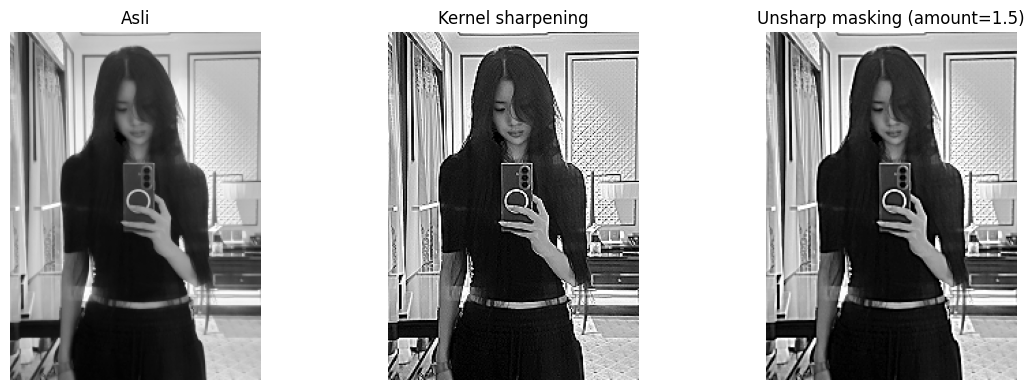

In [ ]:
k_sharp = np.array([[0, -1, 0],
                    [-1, 5, -1],
                    [0, -1, 0]], dtype=np.float64)
sharp_kernel = to_uint8(convolve2d(img, k_sharp))

blurred = convolve2d(img, gaussian_kernel(5, 1.5))
unsharp = to_uint8(img + 1.5 * (img - blurred))

show([img, sharp_kernel, unsharp], ['Asli', 'Kernel sharpening', 'Unsharp masking (amount=1.5)'])

## 3. Edge detection

### 3.1 Sobel dan Prewitt (turunan orde pertama)

Hitung Gx dan Gy dengan konvolusi, lalu magnitude `sqrt(Gx^2 + Gy^2)` dan arah `atan2(Gy, Gx)`.

Catatan: karena `convolve2d` melakukan flip kernel, tanda Gx/Gy bisa terbalik dibanding korelasi. Magnitude tidak terpengaruh, arah hanya bergeser 180 derajat.

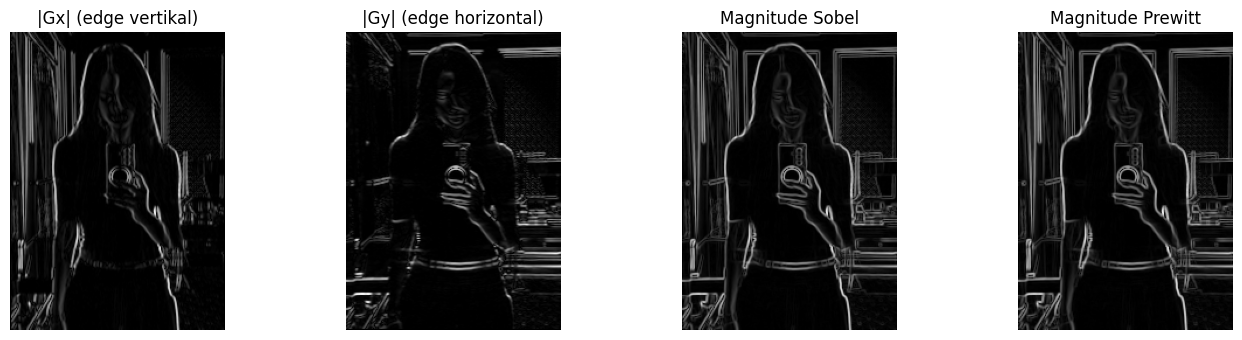

In [ ]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float64)
sobel_y = sobel_x.T

prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]], dtype=np.float64)
prewitt_y = prewitt_x.T


def gradient(image, kx, ky):
    gx = convolve2d(image, kx)
    gy = convolve2d(image, ky)
    mag = np.hypot(gx, gy)
    ang = np.arctan2(gy, gx)
    return gx, gy, mag, ang


gx, gy, mag_s, ang_s = gradient(img, sobel_x, sobel_y)
_, _, mag_p, _ = gradient(img, prewitt_x, prewitt_y)

show([normalize_to_uint8(np.abs(gx)), normalize_to_uint8(np.abs(gy)),
      normalize_to_uint8(mag_s), normalize_to_uint8(mag_p)],
     ['|Gx| (edge vertikal)', '|Gy| (edge horizontal)', 'Magnitude Sobel', 'Magnitude Prewitt'],
     cols=4, size=(3.5, 3.5))

Bandingkan dengan `cv2.Sobel`, lalu terapkan threshold pada magnitude untuk mendapat peta edge biner.

Selisih magnitude manual vs cv2.Sobel: 0.00e+00


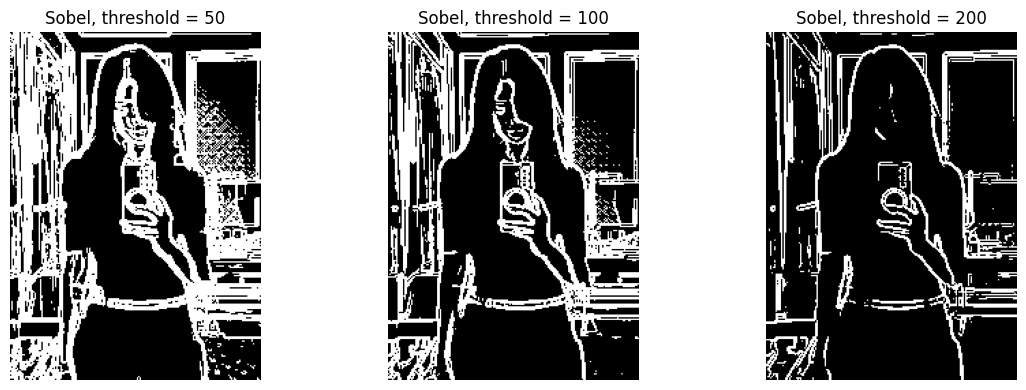

In [ ]:
cx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
cy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
mag_cv = np.hypot(cx, cy)
print(f'Selisih magnitude manual vs cv2.Sobel: {np.abs(mag_s - mag_cv).max():.2e}')

thresholds = [50, 100, 200]
show([((mag_s > t) * 255).astype(np.uint8) for t in thresholds],
     [f'Sobel, threshold = {t}' for t in thresholds])

### 3.2 Pengaruh noise terhadap edge detection

Turunan memperbesar noise. Lihat bedanya Sobel pada gambar noisy tanpa dan dengan blur Gaussian terlebih dahulu.

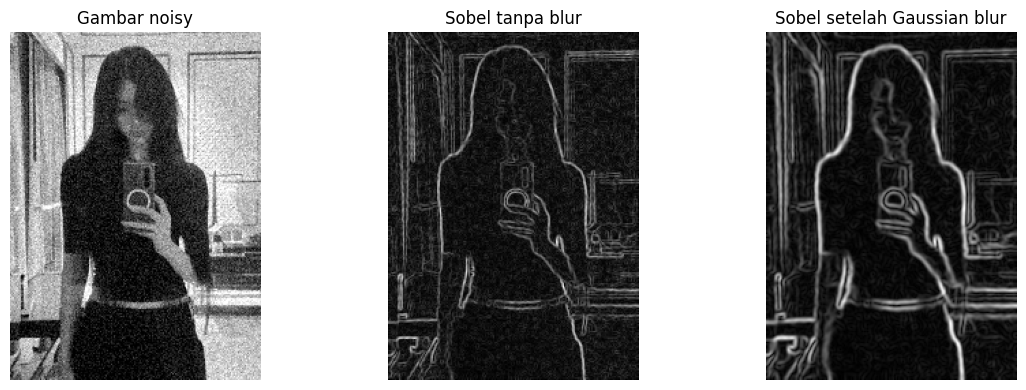

In [ ]:
_, _, mag_noisy, _ = gradient(noisy_g, sobel_x, sobel_y)

smoothed = convolve2d(noisy_g, gaussian_kernel(5, 1.2))
_, _, mag_smooth, _ = gradient(smoothed, sobel_x, sobel_y)

show([noisy_g, normalize_to_uint8(mag_noisy), normalize_to_uint8(mag_smooth)],
     ['Gambar noisy', 'Sobel tanpa blur', 'Sobel setelah Gaussian blur'])

### 3.3 Laplacian dan LoG (turunan orde kedua)

Laplacian sangat sensitif noise, jadi dipasangkan dengan Gaussian (LoG). Edge dicari di titik **zero-crossing**, yaitu tempat nilai berganti tanda.

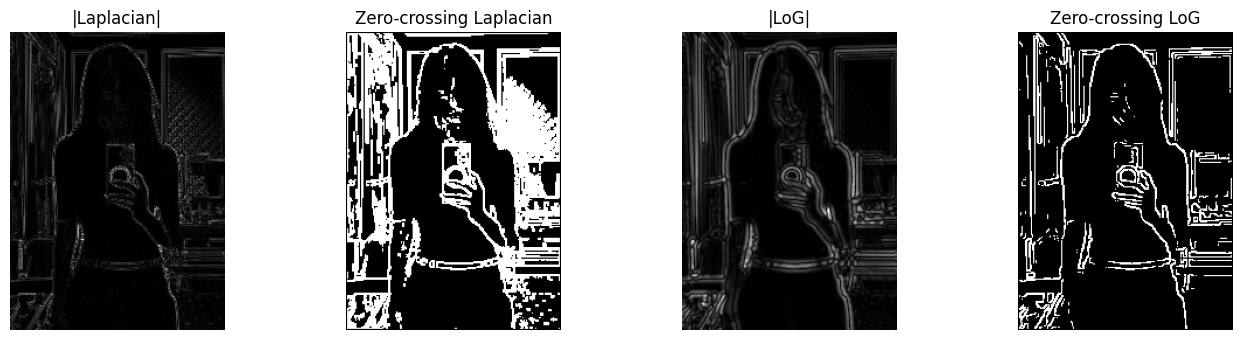

In [ ]:
k_lap = np.array([[0, 1, 0],
                  [1, -4, 1],
                  [0, 1, 0]], dtype=np.float64)


@njit
def zero_crossing(lap, thr=5.0):
    out = np.zeros(lap.shape, dtype=np.uint8)
    h, w = lap.shape
    for y in range(1, h - 1):
        for x in range(1, w - 1):
            patch = lap[y - 1:y + 2, x - 1:x + 2]
            if patch.max() > thr and patch.min() < -thr:
                out[y, x] = 255
    return out


lap_raw = convolve2d(img, k_lap)
log_resp = convolve2d(convolve2d(img, gaussian_kernel(7, 1.4)), k_lap)

show([normalize_to_uint8(np.abs(lap_raw)), zero_crossing(lap_raw, 20),
      normalize_to_uint8(np.abs(log_resp)), zero_crossing(log_resp, 5)],
     ['|Laplacian|', 'Zero-crossing Laplacian', '|LoG|', 'Zero-crossing LoG'],
     cols=4, size=(3.5, 3.5))

### 3.4 Canny (OpenCV)

Tahapan internal: Gaussian blur, gradien, non-maximum suppression, double threshold, hysteresis. Di sini kita pakai `cv2.Canny` dan eksperimen dengan dua threshold-nya.

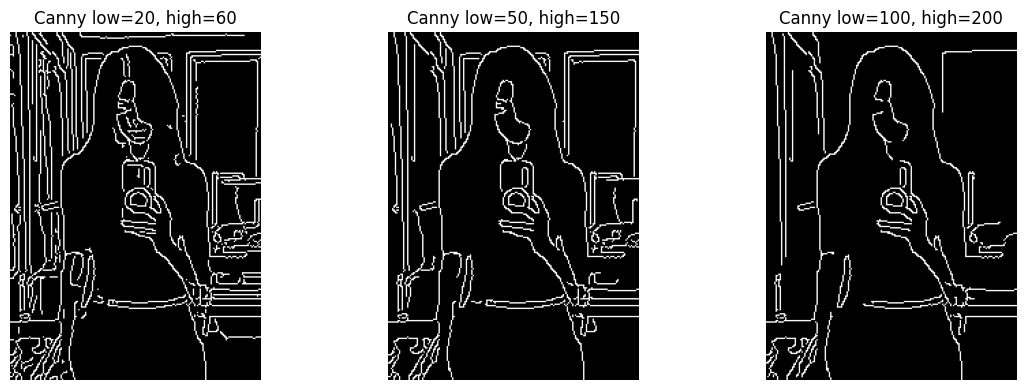

In [ ]:
blur = cv2.GaussianBlur(img, (5, 5), 1.4)

params = [(20, 60), (50, 150), (100, 200)]
show([cv2.Canny(blur, lo, hi) for lo, hi in params],
     [f'Canny low={lo}, high={hi}' for lo, hi in params])

## 4. Perbandingan akhir pada gambar ber-noise

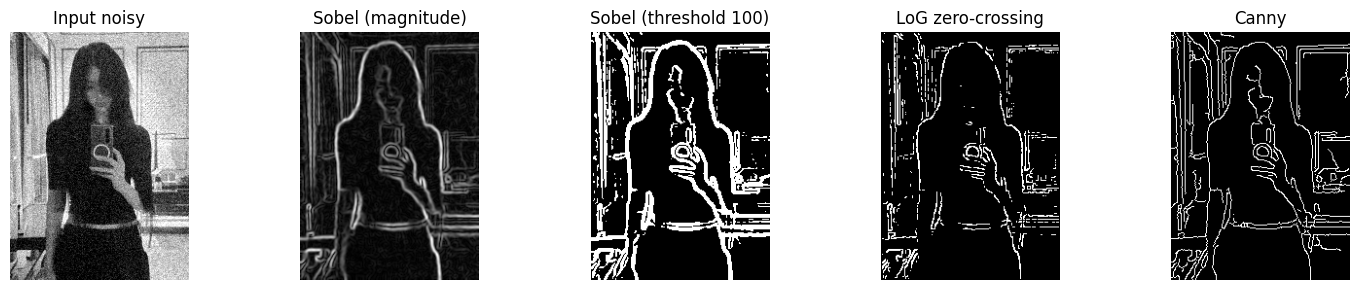

In [ ]:
blur_n = cv2.GaussianBlur(noisy_g, (5, 5), 1.4)

sobel_result = normalize_to_uint8(mag_smooth)
sobel_binary = ((mag_smooth > 100) * 255).astype(np.uint8)
canny_result = cv2.Canny(blur_n, 50, 150)
log_result = zero_crossing(convolve2d(convolve2d(noisy_g, gaussian_kernel(7, 1.4)), k_lap), 8)

show([noisy_g, sobel_result, sobel_binary, log_result, canny_result],
     ['Input noisy', 'Sobel (magnitude)', 'Sobel (threshold 100)', 'LoG zero-crossing', 'Canny'],
     cols=5, size=(3, 3))

## 5. Bonus: Hapus background

Tiga pendekatan klasik, dari yang paling sederhana ke yang paling kuat. Semuanya berujung pada satu hal: **mask biner** (putih = objek, hitam = background), lalu mask itu dipakai untuk memotong gambar.

| Metode | Ide | Cocok untuk |
|---|---|---|
| A. Threshold (Otsu) | pisahkan berdasar terang/gelap | objek kontras jelas dengan background polos |
| B. Edge + contour | Canny, tutup celah, isi kontur terbesar | objek dengan tepi tegas dan background bersih |
| C. GrabCut | model warna foreground vs background, dioptimasi iteratif | gambar umum (pakai kotak di sekitar objek) |

Pakai gambar **berwarna** di bagian ini. Untuk gambar sendiri: `cv2.imread(...)` menghasilkan BGR, jadi ubah ke RGB dengan `cv2.cvtColor(x, cv2.COLOR_BGR2RGB)`.

In [ ]:
# Gambar berwarna (RGB). Ganti dengan gambar sendiri jika perlu:
# img_color = cv2.cvtColor(cv2.imread('gambarku.jpg'), cv2.COLOR_BGR2RGB)
img_color = cv2.cvtColor(cv2.imread('h2hjuun.jpg'), cv2.COLOR_BGR2RGB)
gray_c = cv2.cvtColor(img_color, cv2.COLOR_RGB2GRAY)
blur_c = cv2.GaussianBlur(gray_c, (5, 5), 0)  # filtering dulu, seperti di materi
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))


def largest_component(mask):
    # Simpan hanya bagian putih terbesar (buang bintik-bintik kecil)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if n <= 1:
        return mask
    k = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return ((lab == k) * 255).astype(np.uint8)


def apply_mask(image, mask, bg=255):
    # Objek dipertahankan, background diganti warna bg (255 = putih)
    return np.where(mask[..., None] > 0, image, bg).astype(np.uint8)


def show_color(images, titles, cols=4, size=(3.5, 3.5)):
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size[0] * cols, size[1] * rows))
    for ax, im, t in zip(np.array(axes).reshape(-1), images, titles):
        ax.imshow(im, cmap='gray' if im.ndim == 2 else None)
        ax.set_title(t)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### A. Threshold (Otsu) + morfologi

Otsu mencari nilai threshold otomatis. Morfologi *close* menutup lubang kecil, *open* membuang bintik. Metode ini hanya melihat **terang/gelap**, jadi gagal kalau objek dan background punya rentang kecerahan yang bercampur.

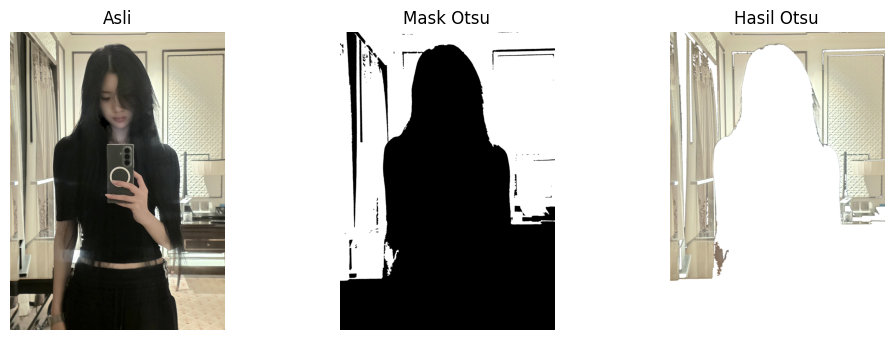

In [ ]:
_, th = cv2.threshold(blur_c, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, kernel)
th = cv2.morphologyEx(th, cv2.MORPH_OPEN, kernel)
mask_otsu = largest_component(th)

show_color([img_color, mask_otsu, apply_mask(img_color, mask_otsu)],
           ['Asli', 'Mask Otsu', 'Hasil Otsu'], cols=3)

### B. Edge detection (Canny) + contour

Tepi dari Canny sering putus-putus, jadi di-*dilate* dulu supaya tersambung. Lalu kontur luar terbesar diisi penuh menjadi mask. Berhasil bila tepi objek jelas dan tidak banyak tepi lain di background.

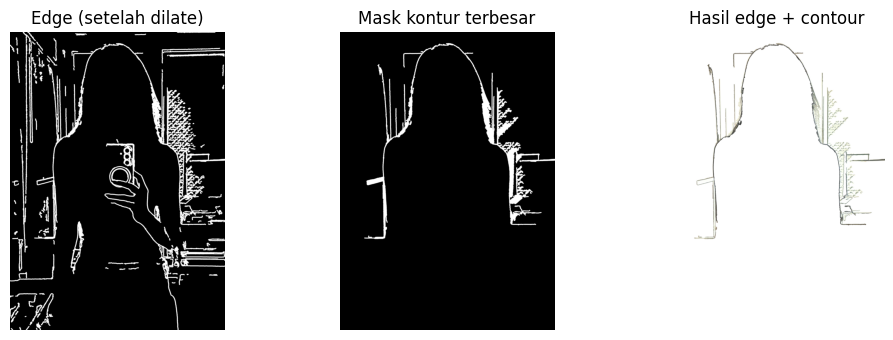

In [ ]:
edges = cv2.Canny(blur_c, 50, 150)
edges = cv2.dilate(edges, kernel, iterations=2)
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

mask_edge = np.zeros_like(gray_c)
cv2.drawContours(mask_edge, [max(contours, key=cv2.contourArea)], -1, 255, cv2.FILLED)

show_color([edges, mask_edge, apply_mask(img_color, mask_edge)],
           ['Edge (setelah dilate)', 'Mask kontur terbesar', 'Hasil edge + contour'], cols=3)

### C. GrabCut

GrabCut butuh **kotak (rect)** yang melingkupi objek: semua di luar kotak pasti background, di dalamnya diperkirakan sendiri lewat model warna (GMM) dan graph cut. Atur `rect = (x, y, lebar, tinggi)` sesuai gambarmu.

Nilai mask GrabCut: 0 = background pasti, 1 = foreground pasti, 2 = kemungkinan background, 3 = kemungkinan foreground.

Ukuran gambar: 2873 x 3993


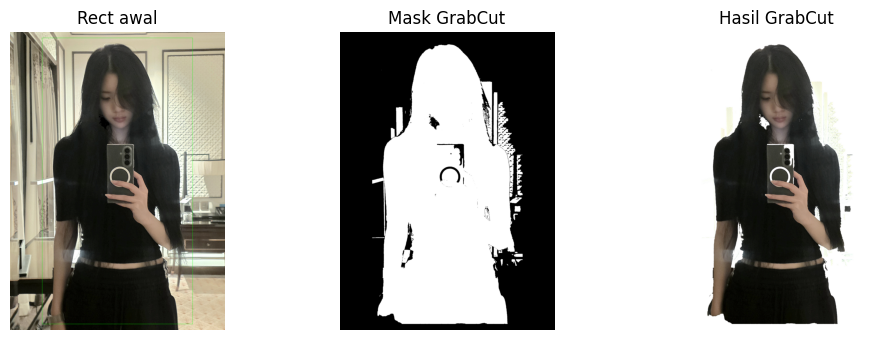

In [ ]:
h, w = img_color.shape[:2]
print('Ukuran gambar:', w, 'x', h)

# (x, y, lebar, tinggi) sebagai pecahan dari ukuran gambar
rect = (int(0.15 * w), int(0.02 * h), int(0.70 * w), int(0.96 * h))

gc_mask = np.zeros(gray_c.shape, np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

bgr = cv2.cvtColor(img_color, cv2.COLOR_RGB2BGR)  # grabCut tidak peduli urutan kanal, ini untuk konsistensi
cv2.grabCut(bgr, gc_mask, rect, bgd_model, fgd_model, 5, cv2.GC_INIT_WITH_RECT)

mask_gc = np.where((gc_mask == 1) | (gc_mask == 3), 255, 0).astype(np.uint8)

preview = img_color.copy()
x, y, w, h = rect
cv2.rectangle(preview, (x, y), (x + w, y + h), (0, 255, 0), 2)

show_color([preview, mask_gc, apply_mask(img_color, mask_gc)],
           ['Rect awal', 'Mask GrabCut', 'Hasil GrabCut'], cols=3)

### Hasil akhir: PNG transparan dan ganti background

Mask dijadikan **alpha channel** supaya background benar-benar transparan, bukan sekadar putih. Mask juga di-blur sedikit supaya tepinya halus (ini lagi-lagi filtering).

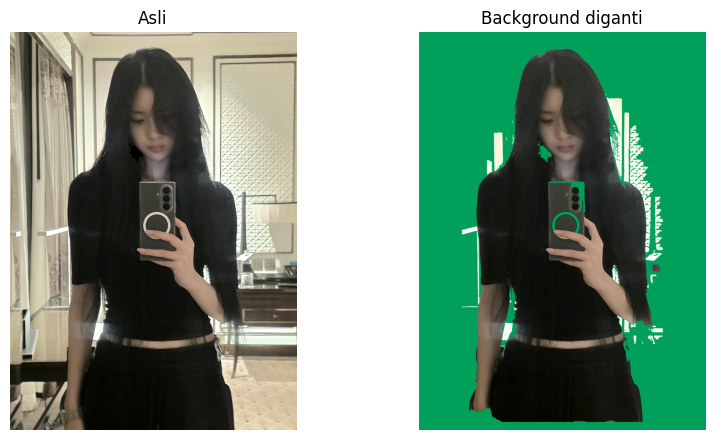

Tersimpan: hasil_tanpa_background.png


In [ ]:
soft = cv2.GaussianBlur(mask_gc, (5, 5), 0)  # tepi halus

rgba = np.dstack([img_color, soft])           # RGB + alpha
cv2.imwrite('hasil_tanpa_background.png', cv2.cvtColor(rgba, cv2.COLOR_RGBA2BGRA))

# Ganti dengan background warna lain (alpha blending)
alpha = (soft / 255.0)[..., None]
green = np.full_like(img_color, (0, 160, 90))
composite = (alpha * img_color + (1 - alpha) * green).astype(np.uint8)

show_color([img_color, composite], ['Asli', 'Background diganti'], cols=2, size=(4.5, 4.5))
print('Tersimpan: hasil_tanpa_background.png')

> **Kalau hasilnya masih kurang bagus:** untuk gambar yang rumit (rambut, bulu, background ramai), metode klasik ada batasnya. Alternatif berbasis deep learning: `pip install rembg`, lalu
> `from rembg import remove; hasil = remove(gambar_pil)`. Tidak butuh rect atau tuning, tapi mengunduh model saat pertama kali dipakai dan lebih berat.